# Boxing DQN: Elvin Cyubahiro's experiments (Learning rate)

This notebook only **launches** experiments. All the DQN code lives in `train.py` in the group repo.

**Before you run:**
- **Colab:** Runtime → Change runtime type → **T4 GPU**.
- **Kaggle:** Settings → Accelerator → **GPU T4 x2** (not P100, which this PyTorch build doesn't support), and turn **Internet on**. For long runs, use **Save Version → Save & Run All** so it keeps running after you close the tab.
- If the repo is private, add a secret named `GITHUB_TOKEN` (Colab: 🔑 Secrets panel, Kaggle: Add-ons → Secrets).
- Edit the config cell, then **Run all**.

Experiments that already have a saved model are skipped, so if the session dies, just run all again.

### What `train.py` supports

```
uv run train.py --lr 1e-4 --gamma 0.99 --batch-size 32 \
                --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 \
                --total-steps 200000 --out-dir models/<name>/exp_01
```

- `--eps-decay` = number of steps over which epsilon falls **linearly** from start to end.
- It must save into `--out-dir`:
  - `dqn_model.pth`: the trained online network's weights
  - `training_log.csv`: one row per episode, with columns `episode,steps,episode_length,reward`
  - `training_plot.png`: reward and episode length over training

## 1. Config

In [1]:
# ===== EDIT THESE =====
MEMBER_NAME = "Elvin_Cyubahiro"   # your real name, used for the models/<name>/ folder and results file
GITHUB_REPO = "github.com/Elvin100s/Formative3_Qlearning.git"   # no https:// prefix
BRANCH = "main"
TOTAL_STEPS = 200_000          # steps per experiment; the epsilon decay values below assume 200k

## 2. Check the GPU

In [2]:
!nvidia-smi -L

GPU 0: Tesla T4 (UUID: GPU-03f5c9ba-23fd-5e05-85b2-22ec2edee52d)


## 3. Where results are saved

In [3]:
import os

# Check Kaggle first: Kaggle's image also has the google.colab package installed
ON_KAGGLE = os.path.exists("/kaggle/working")
ON_COLAB = False
if not ON_KAGGLE:
    try:
        import google.colab  # noqa: F401
        ON_COLAB = True
    except ImportError:
        pass

if ON_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    SAVE_DIR = "/content/drive/MyDrive/boxing-dqn-results"   # survives disconnects
elif ON_KAGGLE:
    SAVE_DIR = "/kaggle/working/results"                    # kept when you Save Version
else:
    SAVE_DIR = os.path.abspath("results")

os.makedirs(SAVE_DIR, exist_ok=True)
print("Saving results to:", SAVE_DIR)

Mounted at /content/drive
Saving results to: /content/drive/MyDrive/boxing-dqn-results


## 4. Get the code and install `uv`

In [4]:
def get_github_token():
    """Reads GITHUB_TOKEN from Colab or Kaggle secrets. Returns None for public repos."""
    try:
        if ON_COLAB:
            from google.colab import userdata
            return userdata.get("GITHUB_TOKEN")
        if ON_KAGGLE:
            from kaggle_secrets import UserSecretsClient
            return UserSecretsClient().get_secret("GITHUB_TOKEN")
    except Exception:
        pass
    return None

# Cloned into /tmp so the token in .git/config never ends up in saved notebook outputs
REPO_DIR = "/tmp/repo"
token = get_github_token()
clone_url = f"https://{token}@{GITHUB_REPO}" if token else f"https://{GITHUB_REPO}"

if os.path.exists(REPO_DIR):
    !git -C {REPO_DIR} pull -q
else:
    !git clone -q -b {BRANCH} {clone_url} {REPO_DIR}

# Install uv (official installer, not pip) and put it on PATH
!curl -LsSf https://astral.sh/uv/install.sh | sh
os.environ["PATH"] = os.path.expanduser("~/.local/bin") + os.pathsep + os.environ["PATH"]

os.chdir(REPO_DIR)
!uv --version
!uv sync

downloading uv 0.13.7 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!
uv 0.13.7 (x86_64-unknown-linux-gnu)
Using CPython 3.13.16 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Resolved 78 packages in 3ms
Prepared 46 packages in 1m 05s
Installed 46 packages in 570ms
 + ale-py==0.12.1
 + cloudpickle==3.1.2
 + contourpy==1.4.0
 + cuda-bindings==13.5.0
 + cuda-pathfinder==1.8.6
 + cuda-toolkit==13.2.2
 + cycler==0.12.1
 + farama-notifications==0.0.6
 + filelock==4.2.9
 + fonttools==4.68.0
 + fsspec==2026.9.0
 + gymnasium==1.4.0
 + jinja2==3.1.6
 + kiwisolver==1.5.1
 + markupsafe==3.0.4
 + matplotlib==3.11.2
 + mpmath==1.3.0
 + networkx==3.7
 + numpy==2.5.4
 + nvidia-cublas==13.4.1.3
 + nvidia-cuda-cccl==13.3.5.0.6
 + nvidia-cuda-cupti==13.2.86
 + nvidia-cuda-nvrtc==13.2.86
 + nvidia-cuda-runtime==13.2.86
 + nvidia-cudnn-cu13==9.26.0.51
 + nvidia-cufft==12.2.0.57
 + nvidia-cufile==1.17.1.22
 + nvidia-cusolver==12.2.0.11
 + nv

## 5. Smoke test: does `train.py` run end to end?

In [5]:
# Stop if PyTorch can't use the GPU, otherwise every run would silently train on the CPU
gpu_check = !uv run python -c "import torch; print('GPU_OK' if torch.cuda.is_available() else 'NO_GPU')"
assert "GPU_OK" in gpu_check, "PyTorch can't see the GPU. Use a T4 GPU (not P100) and run again."

SMOKE_DIR = "/tmp/smoke_test"
# 3,000 steps with learning starting at step 500, so the update code actually runs.
# MPLBACKEND=Agg: Kaggle/Colab set it to their notebook backend, which train.py's environment lacks.
!MPLBACKEND=Agg uv run train.py --total-steps 3000 --learning-starts 500 --out-dir {SMOKE_DIR}

assert os.path.exists(os.path.join(SMOKE_DIR, "dqn_model.pth")), "train.py did not save dqn_model.pth. Fix it before running experiments."
assert os.path.exists(os.path.join(SMOKE_DIR, "training_log.csv")), "train.py did not save training_log.csv."
print("Smoke test passed.")

Training on cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | step     1780 | length  1780 | reward   -6.0 | epsilon 0.983
Done. Model and logs saved to /tmp/smoke_test
Smoke test passed.


## 6. Experiments: Learning rate

Everything starts from the shared baseline (lr 1e-4, gamma 0.99, batch 32, epsilon 1.0 → 0.05 over 100k steps), and each experiment changes one or two things. Edit freely, but keep all 10 different.

In [6]:
EXPERIMENTS = [
    {"id": 1, "lr": 0.0001, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Baseline'},
    {"id": 2, "lr": 5e-05, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Lower LR'},
    {"id": 3, "lr": 0.00025, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Higher LR'},
    {"id": 4, "lr": 0.0005, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'High LR'},
    {"id": 5, "lr": 0.001, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Very high LR (expect instability)'},
    {"id": 6, "lr": 1e-05, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Very low LR (expect slow learning)'},
    {"id": 7, "lr": 0.0001, "gamma": 0.98, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Shorter horizon (gamma 0.98)'},
    {"id": 8, "lr": 0.0001, "gamma": 0.99, "batch_size": 64, "eps_start": 1.0, "eps_end": 0.05, "eps_decay": 100000, "note": 'Baseline LR + bigger batch'},
    {"id": 9, "lr": 0.0001, "gamma": 0.99, "batch_size": 32, "eps_start": 0.8, "eps_end": 0.05, "eps_decay": 100000, "note": 'Lower starting epsilon'},
    {"id": 10, "lr": 0.0001, "gamma": 0.99, "batch_size": 32, "eps_start": 1.0, "eps_end": 0.02, "eps_decay": 150000, "note": 'Explore longer, finish greedier'},
]

## 7. Run them

In [7]:
import shlex

def experiment_dir(exp_id):
    return os.path.join(SAVE_DIR, "models", MEMBER_NAME, f"exp_{exp_id:02d}")

for exp in EXPERIMENTS:
    out_dir = experiment_dir(exp["id"])
    if os.path.exists(os.path.join(out_dir, "dqn_model.pth")):
        print(f"Experiment {exp['id']} already done, skipping.")
        continue

    cmd = (
        f"MPLBACKEND=Agg uv run train.py --lr {exp['lr']} --gamma {exp['gamma']} --batch-size {exp['batch_size']} "
        f"--eps-start {exp['eps_start']} --eps-end {exp['eps_end']} --eps-decay {exp['eps_decay']} "
        f"--total-steps {TOTAL_STEPS} --out-dir {shlex.quote(out_dir)}"
    )
    print(f"\n=== Experiment {exp['id']}: {exp['note']} ===\n{cmd}\n")
    !{cmd}


=== Experiment 1: Baseline ===
MPLBACKEND=Agg uv run train.py --lr 0.0001 --gamma 0.99 --batch-size 32 --eps-start 1.0 --eps-end 0.05 --eps-decay 100000 --total-steps 200000 --out-dir /content/drive/MyDrive/boxing-dqn-results/models/Elvin_Cyubahiro/exp_01

Training on cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
Episode    1 | step     1780 | length  1780 | reward   -7.0 | epsilon 0.983
Episode    2 | step     3565 | length  1785 | reward    2.0 | epsilon 0.966
Episode    3 | step     5350 | length  1785 | reward   -2.0 | epsilon 0.949
Episode    4 | step     7128 | length  1778 | reward   10.0 | epsilon 0.932
Episode    5 | step     8911 | length  1783 | reward    8.0 | epsilon 0.915
Episode    6 | step    10691 | length  1780 | reward    2.0 | epsilon 0.898
Episode    7 | step    12476 | length  1785 | reward   -4.0 | epsilon 0.881
Episode    8 | step    14261 | length  1785 | reward    0.0 | epsilon 0.865
Episode    9 | step    16042 | length

## 8. Plot every experiment

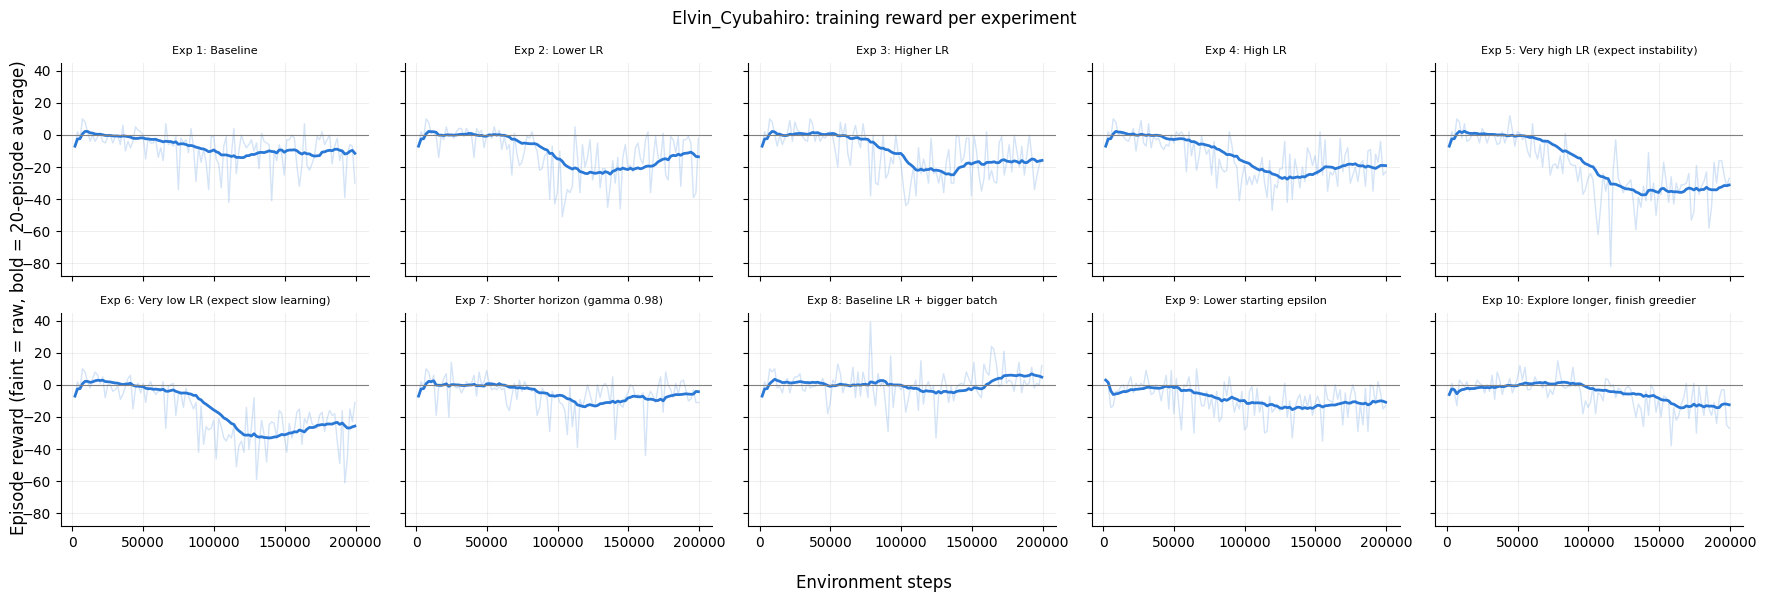

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

PLOT_DIR = os.path.join(SAVE_DIR, "plots")
os.makedirs(PLOT_DIR, exist_ok=True)

logs = {}
for exp in EXPERIMENTS:
    path = os.path.join(experiment_dir(exp["id"]), "training_log.csv")
    if os.path.exists(path):
        logs[exp["id"]] = pd.read_csv(path)

# One small panel per experiment, same y-axis, so they compare at a glance
fig, axes = plt.subplots(2, 5, figsize=(18, 6), sharex=True, sharey=True)
for ax, exp in zip(axes.flat, EXPERIMENTS):
    ax.set_title(f"Exp {exp['id']}: {exp['note']}", fontsize=8)
    ax.grid(alpha=0.2)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    if exp["id"] not in logs:
        ax.text(0.5, 0.5, "not run yet", ha="center", va="center", transform=ax.transAxes, color="gray")
        continue
    log = logs[exp["id"]]
    ax.plot(log["steps"], log["reward"], color="#2a78d6", alpha=0.2, linewidth=1)
    ax.plot(log["steps"], log["reward"].rolling(20, min_periods=1).mean(), color="#2a78d6", linewidth=2)
    ax.axhline(0, color="gray", linewidth=0.8)

fig.supxlabel("Environment steps")
fig.supylabel("Episode reward (faint = raw, bold = 20-episode average)")
fig.suptitle(f"{MEMBER_NAME}: training reward per experiment")
fig.tight_layout()
fig.savefig(os.path.join(PLOT_DIR, f"{MEMBER_NAME}_experiments.png"), dpi=150)
plt.show()

## 9. Draft the results table

This fills in the numbers. **Write the "Observed behaviour" column yourself**, from the plots. That's what the coach grades, and you'll have to explain it in the presentation.

In [9]:
from IPython.display import display


def lr_text(lr):
    return format(lr, "f").rstrip("0")   # 5e-05 -> 0.00005, so every learning rate reads the same way


rows, end_rewards = [], {}   # end_rewards: experiment id -> average reward over its last 20 rounds
for exp in EXPERIMENTS:
    row = {
        "Experiment": exp["id"],
        "Learning rate": lr_text(exp["lr"]),
        "Gamma": exp["gamma"],
        "Batch size": exp["batch_size"],
        "Epsilon start": exp["eps_start"],
        "Epsilon end": exp["eps_end"],
        "Epsilon decay (steps)": f"{exp['eps_decay']:,}",
        "Start: first 20 rounds": "-",
        "Low point (20-round avg)": "-",
        "End: last 20 rounds": "-",
        "Wins in last 20": "-",
        "Observed behaviour": "TODO",
    }
    log = logs.get(exp["id"])
    if log is not None and len(log) >= 20:
        rewards = log["reward"]
        avg20 = rewards.rolling(20).mean()   # average of each 20 rounds in a row
        low_step = log.loc[avg20.idxmin(), "steps"]
        end_rewards[exp["id"]] = rewards.tail(20).mean()
        row["Start: first 20 rounds"] = f"{rewards.head(20).mean():+.1f}"
        row["Low point (20-round avg)"] = f"{avg20.min():+.1f} at {low_step // 1000}k"
        row["End: last 20 rounds"] = f"{end_rewards[exp['id']]:+.1f}"
        row["Wins in last 20"] = f"{(rewards.tail(20) > 0).sum()}/20"
    rows.append(row)

# A real table in Colab, Kaggle and on GitHub
display(pd.DataFrame(rows).set_index("Experiment"))

summary = ""
if end_rewards:
    best_id = max(end_rewards, key=end_rewards.get)
    worst_id = min(end_rewards, key=end_rewards.get)
    summary = (f"Best: Experiment {best_id} (end {end_rewards[best_id]:+.1f}).  "
               f"Worst: Experiment {worst_id} (end {end_rewards[worst_id]:+.1f}).")
    print(summary)

# The same table as a Markdown file for the repo
display_name = MEMBER_NAME.replace("_", " ")
lines = [
    f"# {display_name}: Hyperparameter Experiment Results",
    "",
    f"**Member:** {display_name} · **Environment:** `ALE/Boxing-v5` · **Each run:** {TOTAL_STEPS:,} steps, same seed",
    "",
    "| " + " | ".join(rows[0].keys()) + " |",
    "|" + "---|" * len(rows[0]),
]
for row in rows:
    lines.append("| " + " | ".join(str(value) for value in row.values()) + " |")
lines += [
    "",
    summary,
    "",
    "**How to read the reward columns.** Reward per round = my points minus the opponent's points, so 0 is a draw. "
    "**Start** = first 20 rounds (mostly random play). **Low point** = worst 20-round average during training. "
    "**End** = last 20 rounds. **Wins** = rounds above 0 among the last 20.",
]

results_path = os.path.join(SAVE_DIR, f"{MEMBER_NAME}_Hyperparameter_experiment_results.md")
with open(results_path, "w") as f:
    f.write("\n".join(lines) + "\n")
print("Saved to", results_path)

,Learning rate,Gamma,Batch size,Epsilon start,Epsilon end,Epsilon decay (steps),Start: first 20 rounds,Low point (20-round avg),End: last 20 rounds,Wins in last 20,Observed behaviour
Experiment,,,,,,,,,,,
1,0.0001,0.99,32,1.0,0.05,"100,000",-0.6,-14.2 at 119k,-11.4,1/20,TODO
2,0.00005,0.99,32,1.0,0.05,"100,000",+0.6,-24.4 at 137k,-13.6,1/20,TODO
3,0.00025,0.99,32,1.0,0.05,"100,000",+0.8,-24.9 at 135k,-15.8,0/20,TODO
4,0.0005,0.99,32,1.0,0.05,"100,000",-0.3,-27.6 at 130k,-19.1,0/20,TODO
5,0.001,0.99,32,1.0,0.05,"100,000",-0.1,-37.4 at 138k,-31.1,0/20,TODO
6,0.00001,0.99,32,1.0,0.05,"100,000",+0.2,-33.0 at 138k,-25.6,0/20,TODO
7,0.0001,0.98,32,1.0,0.05,"100,000",-0.3,-13.7 at 119k,-4.2,5/20,TODO
8,0.0001,0.99,64,1.0,0.05,"100,000",+1.3,-5.2 at 124k,+4.8,13/20,TODO
9,0.0001,0.99,32,0.8,0.05,"100,000",-1.9,-15.4 at 133k,-10.8,1/20,TODO


Best: Experiment 8 (end +4.8).  Worst: Experiment 5 (end -31.1).


## 10. Zip everything to download and commit to the repo

In [10]:
import shutil

# Zip outside SAVE_DIR so the archive doesn't try to include itself
zip_path = shutil.make_archive(f"/tmp/{MEMBER_NAME}_results", "zip", SAVE_DIR)

if ON_COLAB:
    from google.colab import files
    files.download(zip_path)          # results are also already in your Google Drive
elif ON_KAGGLE:
    shutil.copy(zip_path, "/kaggle/working/")   # appears in the notebook's Output tab
print("Zipped:", zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Zipped: /tmp/Elvin_Cyubahiro_results.zip
